#### Import relevant libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

#### Load dataset

In [2]:
marketing_data = pd.read_csv("data/marketing_campaign.csv")

#### Subset for relevant columns

In [3]:
marketing_data = marketing_data[['MntWines','MntFruits', 'MntMeatProducts', 'MntFishProducts', 
                                 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 
                                 'NumWebPurchases','NumCatalogPurchases', 'NumStorePurchases', 
                                 'NumWebVisitsMonth']]

#### Inspect first 5 rows and data types of the dataset

In [4]:
marketing_data.head()

,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth
0,635,88,546,172,88,88,3,8,10,4,7
1,11,1,6,2,1,6,2,1,1,2,5
2,426,49,127,111,21,42,1,8,2,10,4
3,11,4,20,10,3,5,2,2,0,4,6
4,173,43,118,46,27,15,5,5,3,6,5


In [5]:
marketing_data.shape

(2240, 11)

In [6]:
marketing_data.dtypes

MntWines               int64
MntFruits              int64
MntMeatProducts        int64
MntFishProducts        int64
MntSweetProducts       int64
MntGoldProds           int64
NumDealsPurchases      int64
NumWebPurchases        int64
NumCatalogPurchases    int64
NumStorePurchases      int64
NumWebVisitsMonth      int64
dtype: object

#### Scale the data

In [7]:
x = marketing_data.values
marketing_data_scaled = StandardScaler().fit_transform(x)

#### Apply PCA to the dataset

In [8]:
pca_marketing = PCA(n_components=6, random_state = 1)
principalComponents_marketing = pca_marketing.fit_transform(marketing_data_scaled)

In [9]:
principal_marketing_data = pd.DataFrame(data = principalComponents_marketing
             , columns = ['principal component 1', 'principal component 2',
                          'principal component 3','principal component 4'
                         ,'principal component 5','principal component 6'])

#### Check the loadings

In [10]:
loadings_df = pd.DataFrame(pca_marketing.components_).T
loadings_df = loadings_df.set_index(marketing_data.columns)
loadings_df

,0,1,2,3,4,5
MntWines,0.327941,0.222837,-0.435535,-0.208662,-0.087749,0.243052
MntFruits,0.323026,-0.130151,0.376355,0.140996,-0.224386,-0.012065
MntMeatProducts,0.354452,-0.130388,-0.209744,0.305524,0.151587,0.354552
MntFishProducts,0.333163,-0.142444,0.345355,0.150907,-0.049328,0.050934
MntSweetProducts,0.321179,-0.104676,0.363038,0.115690,-0.350306,0.047819
MntGoldProds,0.265813,0.189065,0.405995,-0.416516,0.693513,-0.128306
NumDealsPurchases,-0.042299,0.636331,0.077169,0.661013,0.144609,-0.268801
NumWebPurchases,0.245131,0.493262,0.039387,-0.358028,-0.270322,0.161445
NumCatalogPurchases,0.360813,0.009298,-0.269517,0.235563,0.316932,0.252435
NumStorePurchases,0.329634,0.187143,-0.241080,-0.112152,-0.297203,-0.574865


In [11]:
loadings_df.where(abs(loadings_df) >= 0.35)

,0,1,2,3,4,5
MntWines,NaN,NaN,-0.435535,NaN,NaN,NaN
MntFruits,NaN,NaN,0.376355,NaN,NaN,NaN
MntMeatProducts,0.354452,NaN,NaN,NaN,NaN,0.354552
MntFishProducts,NaN,NaN,NaN,NaN,NaN,NaN
MntSweetProducts,NaN,NaN,0.363038,NaN,-0.350306,NaN
MntGoldProds,NaN,NaN,0.405995,-0.416516,0.693513,NaN
NumDealsPurchases,NaN,0.636331,NaN,0.661013,NaN,NaN
NumWebPurchases,NaN,0.493262,NaN,-0.358028,NaN,NaN
NumCatalogPurchases,0.360813,NaN,NaN,NaN,NaN,NaN
NumStorePurchases,NaN,NaN,NaN,NaN,NaN,-0.574865


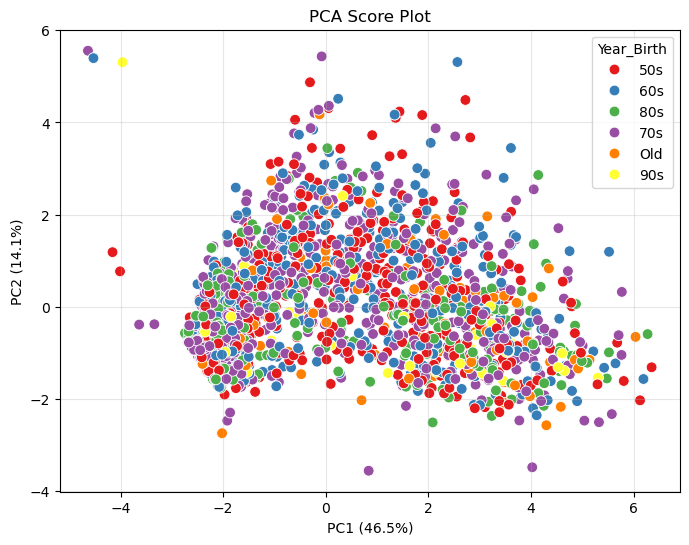

In [56]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

marketing_data_ini = pd.read_csv("data/marketing_campaign.csv")
marketing_data = marketing_data_ini[['MntWines','MntFruits', 'MntMeatProducts', 'MntFishProducts', 
                                 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 
                                 'NumWebPurchases','NumCatalogPurchases', 'NumStorePurchases', 
                                 'NumWebVisitsMonth']]
x = marketing_data.values
marketing_data_scaled = StandardScaler().fit_transform(x)
pca_marketing = PCA(n_components=5, random_state = 1)
principalComponents_marketing = pca_marketing.fit_transform(marketing_data_scaled)
principal_marketing_data = pd.DataFrame(data = principalComponents_marketing
             , columns = ['principal component 1', 'principal component 2',
                          'principal component 3','principal component 4'
                         ,'principal component 5'])

conditions = [
    (marketing_data_ini['Year_Birth'] >= 2000),
    (marketing_data_ini['Year_Birth'] >= 1990) & (marketing_data_ini['Year_Birth'] < 2000),
    (marketing_data_ini['Year_Birth'] >= 1980) & (marketing_data_ini['Year_Birth'] < 1990),
    (marketing_data_ini['Year_Birth'] >= 1970) & (marketing_data_ini['Year_Birth'] < 1980),
    (marketing_data_ini['Year_Birth'] >= 1960) & (marketing_data_ini['Year_Birth'] < 1970),
    (marketing_data_ini['Year_Birth'] >= 1950) & (marketing_data_ini['Year_Birth'] < 1960)
]
choices = ['Baby', '90s', '80s', '70s', '60s', '50s']
principal_marketing_data['Year_Birth'] = np.select(conditions, choices, default='Old')
plt.figure(figsize=(8, 6))
sns.scatterplot(data=principal_marketing_data, x='principal component 1', y='principal component 2', hue='Year_Birth', palette='Set1', s=60)

# Add variance percentages to the axes
var_explained = pca_marketing.explained_variance_ratio_ * 100
plt.xlabel(f"PC1 ({var_explained[0]:.1f}%)")
plt.ylabel(f"PC2 ({var_explained[1]:.1f}%)")
plt.title("PCA Score Plot")
plt.grid(True, alpha=0.3)
plt.show()